## Deep Neural Networks(DNN)

#### 8.1. gradient 기울기 소실 문제
- 심층 신경망에서 gradient가 전달되다가 점차 0에 가까워짐
- 예를 들어, 시그모이드 활성화 함수 특성상 아주 큰 값이나 작은 값이 들어오면 미분값이 거의 0이 됌
- 이를 해결하기 위해 심층 신경망에서 ReLu함수를 활용
- @https://playground.tensorflow.org

In [45]:
import numpy as np
# import tensorflow as tf, keras
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.layers import Normalization 

#### 8.2. 손실함수 선택 문제와 softmax 활성화 함수

- softmax 함수 : $\frac{e^{2.0}}{e^{2.0}+e^{1.0}+e^{0.1}}$
  - 0일 확률 0.1, 1일 확률 0.7, 0일 확률 0.2
  - 큰 값은 더 커지고, 작은 값은 더 작아지는 특성
  - 정보이론에서의 불확실성 척도
  - 손실확률 분포 : Cross Entropy = $H(p, q) = -\Sigma_{x}p(x)log_{n}{q(x)}$
  
- maximum likelihood estimation : $p(d|x) = p(d=1|x)^{d} \cdots p(d=0|x)^{1-d}$
  - 주어진 데이터를 바르게 예측할 확률을 최대화한 것
  
- cross entropy loss
  - 다중 클래스 분류 문제에서 모델의 출력을 softmax 함수를 통해 확률값으로 변환 후, 실제 레이블과의 차이를 최소화하기 위해 사용
  - 이진 교차 엔트로피(BCE) 
  - categorical cross entropy

In [ ]:
# binary Cross Entropy 

y_true = [ [1], [0], [0], [1] ]
y_pred = [ [0.8], [0.3], [0.5], [0.9] ]
binaryCrossEntropy = tf.keras.losses.BinaryCrossentropy()
print(
    binaryCrossEntropy(y_true, y_pred).numpy()
)

0.34458154


In [ ]:
# categorical Cross Entropy

y_true = [ [0.0, 1.0, 0.0], [0.0, 0.0, 1.0], [1.0, 0.0, 0.0] ]
y_pred = [ [0.6, 0.3, 0.1], [0.3, 0.6, 0.1], [0.1, 0.7, 0.2] ]
categoricalCrossEntropy = tf.keras.losses.CategoricalCrossentropy()
print(
    categoricalCrossEntropy(y_true, y_pred).numpy()
)

1.936381


In [ ]:
# sparse Cross Entropy

y_true = np.array([1, 2, 0], dtype = np.int32) 
y_pred = np.array([ [0.6, 0.3, 0.1], [0.3, 0.6, 0.1], [0.1, 0.7, 0.2] ], dtype = np.int32) 
sparseCrossEntropy = tf.keras.losses.serializeSparseCategoricalCrossentropy()
print(
    sparseCrossEntropy(y_true, y_pred).numpy()
) # raise ValueError("Structures don't have the same nested structure.")

1.0986123


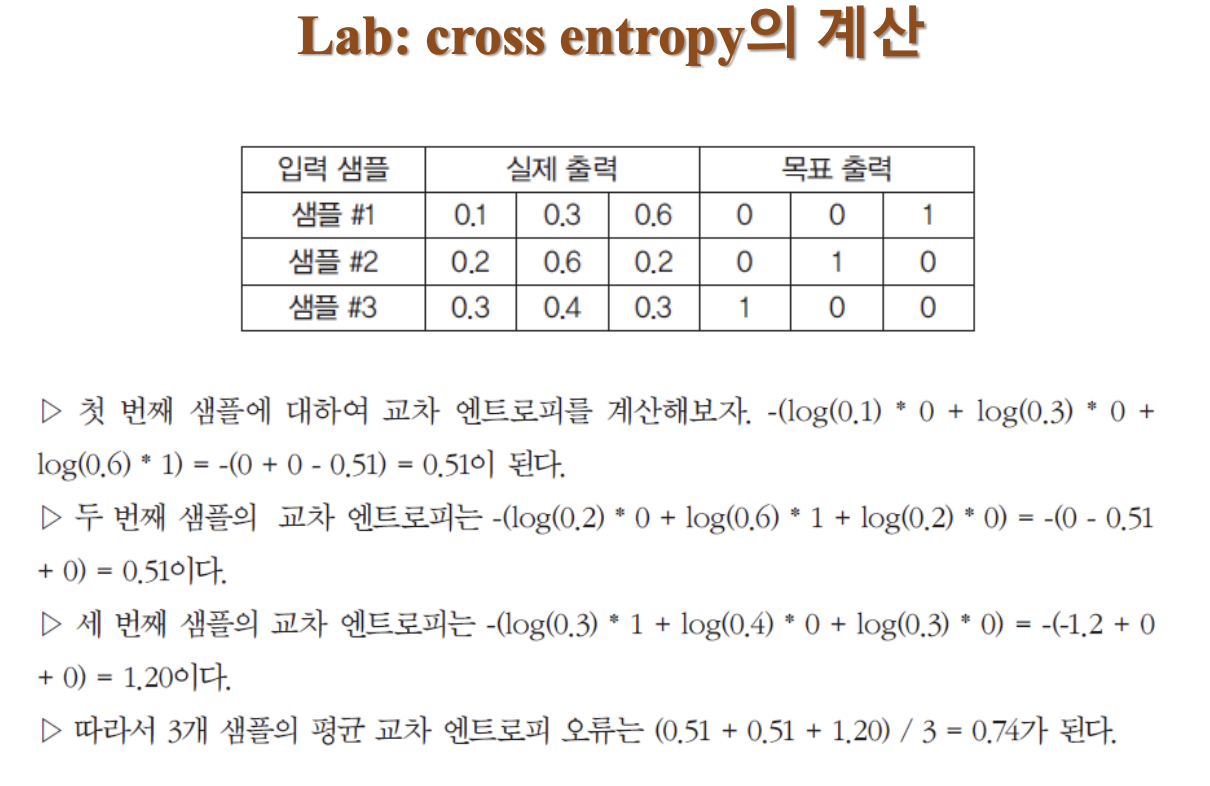

---

#### 8.3. 가중치 초기화 문제 + 데이터 스케일링 방법

- 난수 가중치 초기값 : $var(W_{i}) = \frac{2}{N_{in} + N_{out}}$
- 범주형 변수 encoding (3) : integer encoding, one hot encoding, embedding

In [32]:
# 정수 encoding

X = np.array( [["Korea", 44, 7200], ["Japan", 27, 4800], ["China", 30, 6100]] )
X_integer_encoding = X.copy()
labelEncoder = LabelEncoder()
X_integer_encoding[:, 0] = labelEncoder.fit_transform(X_integer_encoding[:, 0])
print(X_integer_encoding)

[['2' '44' '7200']
 ['1' '27' '4800']
 ['0' '30' '6100']]


In [ ]:
# onehot encoding

X_onehot_encoding = X.copy()
oneHotEncoder = OneHotEncoder()
# to_categorical()
XX = oneHotEncoder.fit_transform(
    X_onehot_encoding[:, 0].reshape(-1, 1)).toarray()
# 원하는 열을 뽑아서 2차원 배열로 만들어서 전달
print(XX)

X_onehot_encoding = np.delete(X_onehot_encoding, [0], axis = 1)
# 0번째 열 삭제
X_onehot_encoding = np.concatenate((XX, X_onehot_encoding), axis = 1)
print(X_onehot_encoding)

[[0. 0. 1.]
 [0. 1. 0.]
 [1. 0. 0.]]
[['0.0' '0.0' '1.0' '44' '7200']
 ['0.0' '1.0' '0.0' '27' '4800']
 ['1.0' '0.0' '0.0' '30' '6100']]
